# Практическая работа 4 "Геометрические трансформации и специальные функции в библиотеке Pillow"

1. Задание: Необходимо повторить весь код из примера с одним своим изображением, что означает, что все манипуляции должны быть произведены с одним изображением.

2. Прикрепить файл в формате .ipynb. 

3. Балл за задание: 3.

## Введение

Вы научитесь применять к изображению геометрические преобразования. Это позволяет выполнять различные операции, такие как преобразование трансляции, то есть сдвиг, изменение формы и поворот изображения. Также вы узнаете, как применять к изображению некоторые базовые операции с массивами и матрицами.

Загрузка изображений для практической работы:

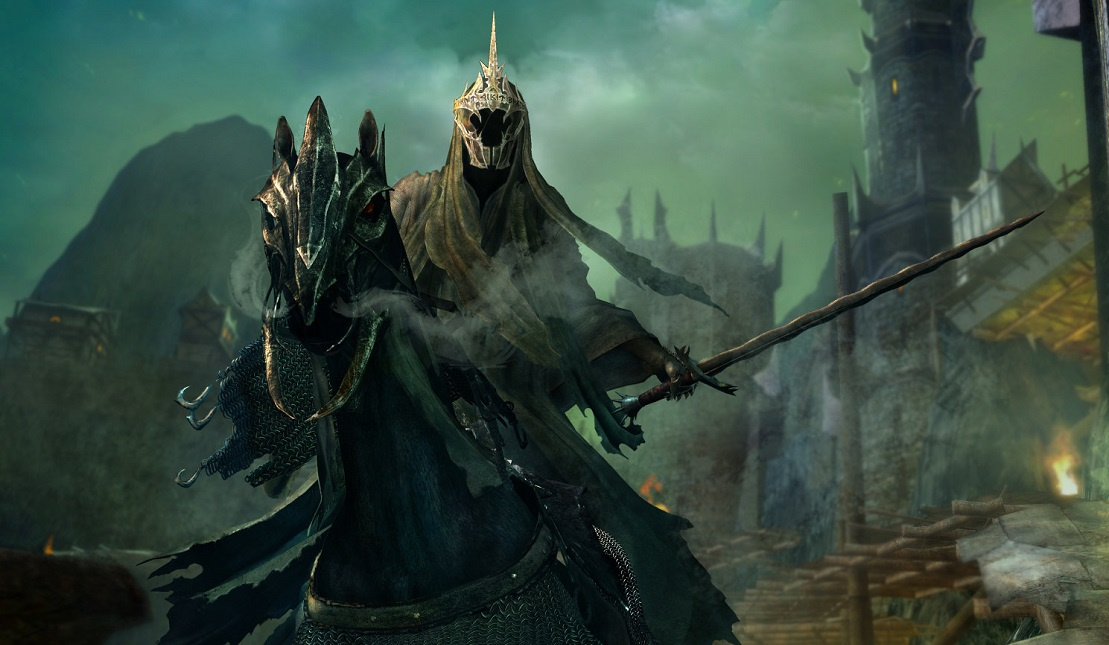

In [2]:
from IPython.display import Image
Image("1.png")

Библиотечки:

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

Во-первых, необходимо определить вспомогательную функцию для построения двух изображений бок о бок.

In [4]:
def plot_image(image_1, image_2,title_1="Orignal",title_2="New Image"):
    plt.figure(figsize=(10,10))
    plt.subplot(1, 2, 1)
    plt.imshow(image_1,cmap="gray")
    plt.title(title_1)
    plt.subplot(1, 2, 2)
    plt.imshow(image_2,cmap="gray")
    plt.title(title_2)
    plt.show()

## Геометрические преобразования

<p>Геометрические преобразования позволяют выполнять различные операции, такие как сдвиг, изменение формы и вращение изображения.
<p>Вы можете изменить размер изображения с помощью метода <code>resize()</code> из <code>PIL</code>, который принимает в качестве параметров изображение с измененным размером <code>width</code> и <code>height</code>.
<p>Рассмотрим следующее изображение:

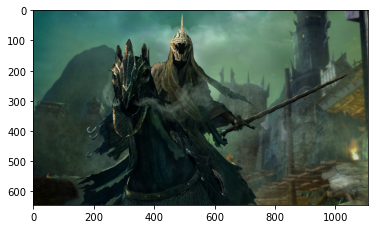

In [5]:
image = Image.open("1.png")
plt.imshow(image)
plt.show()

Вы можете масштабировать горизонтальную ось на два и оставить вертикальную ось как есть:

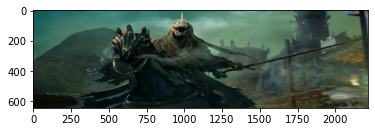

In [6]:
width, height = image.size
new_width = 2 * width
new_hight = height
new_image = image.resize((new_width, new_hight))
plt.imshow(new_image)
plt.show()

Таким же образом вы можете масштабировать вертикальную ось на два:

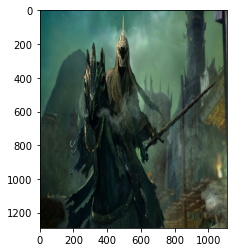

In [7]:
new_width = width
new_hight = 2 * height
new_image = image.resize((new_width, new_hight))
plt.imshow(new_image)
plt.show()

Вы можете удвоить ширину и высоту изображения:

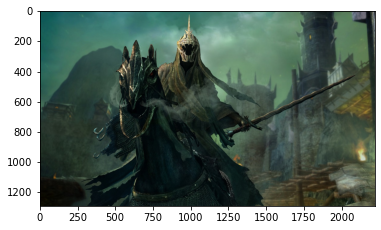

In [8]:
new_width = 2 * width
new_hight = 2 * height
new_image = image.resize((new_width, new_hight))
plt.imshow(new_image)
plt.show()

Вы также можете уменьшить ширину и высоту изображения на 1/2:

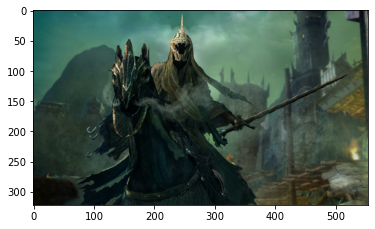

In [9]:
new_width = width // 2
new_hight = height // 2

new_image = image.resize((new_width, new_hight))
plt.imshow(new_image)
plt.show()

## Вращение

Мы можем повернуть изображение на угол $\theta$, используя метод `rotate`.

Повернем изображение на 45 градусов:

In [10]:
theta = 45
new_image = image.rotate(theta)

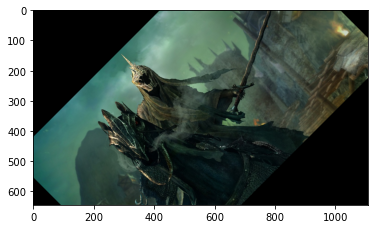

In [11]:
plt.imshow(new_image)
plt.show()

## Математические операции

### Операции с массивами

<p>Вы можете выполнять операции с массивом изображения, используя широковещательную передачу Python, а также добавить константу к значению интенсивности каждого пикселя.
<p>Перед этим вы должны сначала преобразовать изображение PIL в массив numpy.

In [12]:
image = np.array(image)

Затем добавляем константу в массив изображений:

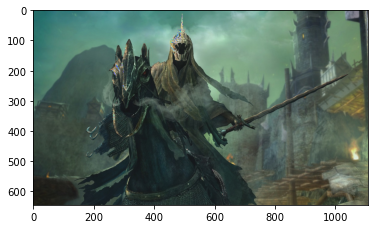

In [14]:
new_image = image + 20
plt.imshow(new_image)
plt.show()

Вы можете умножить значение интенсивности каждого пикселя на постоянное значение.

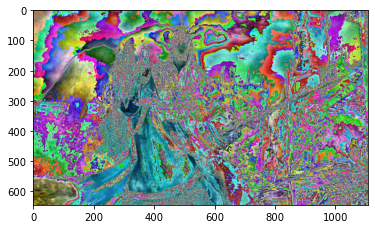

In [15]:
new_image = 10 * image
plt.imshow(new_image)
plt.show()

Вы можете складывать элементы двух массивов одинаковой формы. В этом примере вы генерируете массив случайных шумов с той же формой и типом данных, что и исходное изображение.

In [16]:
Noise = np.random.normal(0, 20, (height, width, 3)).astype(np.uint8)
Noise.shape

(645, 1109, 3)

Далее добавляем сгенерированный шум к изображению и отображаем. Вы видите можете увидеть как испортилось изображение:

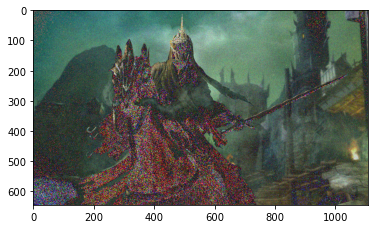

In [17]:
new_image = image + Noise

plt.imshow(new_image)
plt.show()

При этом вы можете перемножать элементы двух массивов одинаковой формы. Вы можете умножить случайное изображение и первое изображение и отобразить результат.

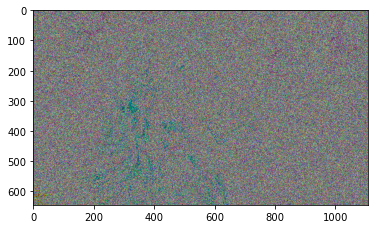

In [18]:
new_image = image*Noise

plt.imshow(new_image)
plt.show()

### Матричные операции

Изображения в градациях серого представляют собой матрицы. Рассмотрим следующее изображение в оттенках серого:

In [19]:
im_gray = Image.open("1.png")

Несмотря на то, что изображение серое, оно имеет три канала. Вы можете преобразовать его в одноканальное изображение.

In [20]:
from PIL import ImageOps

In [21]:
im_gray = ImageOps.grayscale(im_gray)

Вы можете преобразовать изображение PIL в массив numpy:

In [22]:
im_gray = np.array(im_gray)

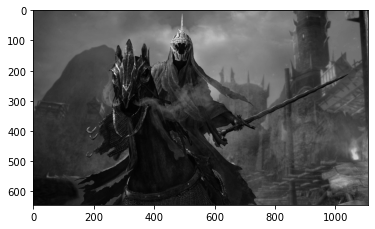

In [23]:
plt.imshow(im_gray,cmap='gray')
plt.show()

Вы можете применять алгоритмы, разработанные для матриц. Вы можете использовать разложение по сингулярным значениям, разлагая матрицу изображения на произведение трех матриц.

In [24]:
U, s, V = np.linalg.svd(im_gray , full_matrices=True)

Можно увидеть, что <code>s</code> не прямоугольной формы:

In [25]:
s.shape

(645,)

Вы можете преобразовать <code>s</code> в диагональную матрицу <code>S</code>:

In [26]:
S = np.zeros((im_gray.shape[0], im_gray.shape[1]))
S[:image.shape[0], :image.shape[0]] = np.diag(s)

Вы можете построить матрицу U и V:

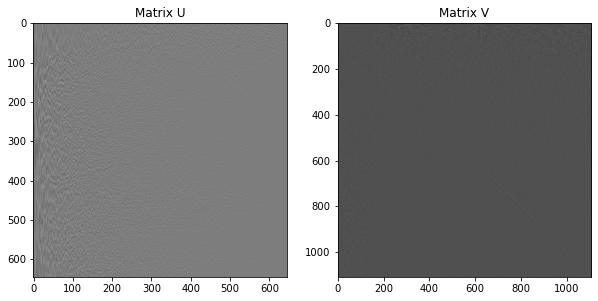

In [27]:
plot_image(U, V, title_1="Matrix U", title_2="Matrix V")

Мы видим, что большинство элементов в S равны нулю:

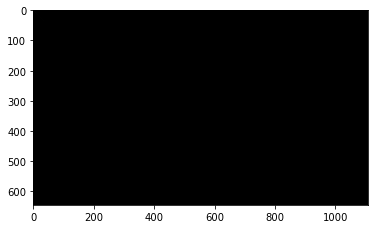

In [28]:
plt.imshow(S, cmap='gray')
plt.show()

Вы можете найти матричное произведение всех матриц. Во-первых, можно выполнить матричное умножение на `S` и `U`, назначить его на `B` и отобразить результат:

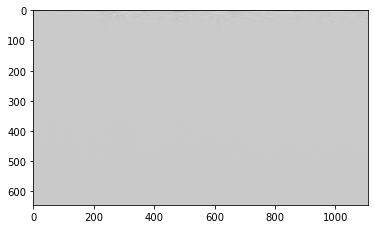

In [29]:
B = S.dot(V)
plt.imshow(B,cmap='gray')
plt.show()

Вы можете найти матричное произведение `U`, `S`, и `B`.Тогда изображение отобразится целиком:

In [30]:
A = U.dot(B)

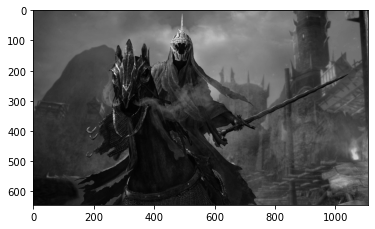

In [31]:
plt.imshow(A,cmap='gray')
plt.show()

Многие элементы избыточны. Вы можете удалить некоторые строки и столбцы `S` и `V` и приблизить изображение:

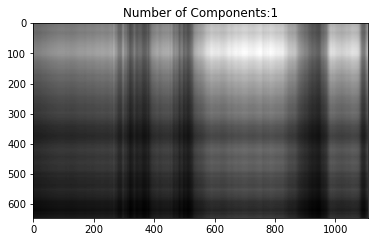

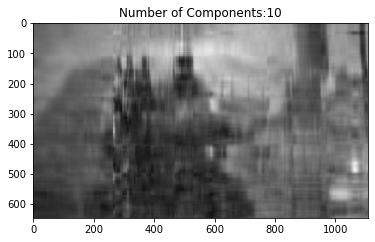

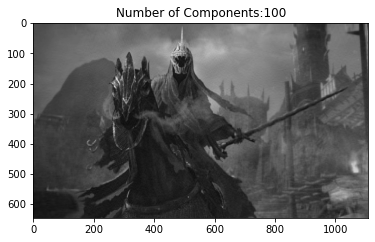

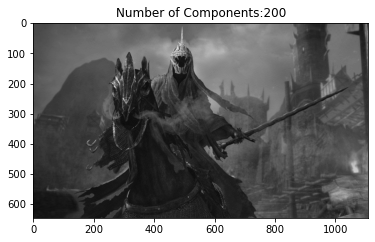

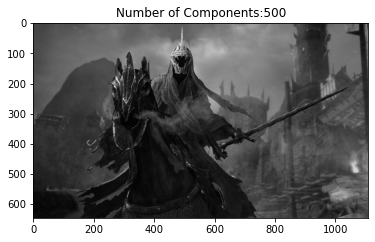

In [32]:
for n_component in [1,10,100,200, 500]:
    S_new = S[:, :n_component]
    V_new = V[:n_component, :]
    A = U.dot(S_new.dot(V_new))
    plt.imshow(A,cmap='gray')
    plt.title("Number of Components:"+str(n_component))
    plt.show()

Можно увидеть, что необходимо всего от 100 до 200 компонентов для представления изображения в удообном виде.

## Пространственные операции при обработке изображений

Пространственные операции используют пиксели в окрестности для определения текущего значения пикселя. Некоторые приложения включают фильтрацию и повышение резкости. Они используются на многих этапах компьютерного зрения, таких как сегментация, и являются ключевым строительным блоком в алгоритмах машинного обучения.

Библиотечки:

In [33]:
# Используется для просмотра изображений
import matplotlib.pyplot as plt
# Используется для загрузки изображения
from PIL import Image
# Используется для создания ядер для фильтрации
import numpy as np

Ниже предсталена функция, которая построит два изображения рядом.

In [34]:
def plot_image(image_1, image_2,title_1="Orignal",title_2="New Image"):
    plt.figure(figsize=(10,10))
    plt.subplot(1, 2, 1)
    plt.imshow(image_1)
    plt.title(title_1)
    plt.subplot(1, 2, 2)
    plt.imshow(image_2)
    plt.title(title_2)
    plt.show()

Пространственные операции используют соседние пиксели для определения текущего значения пикселя.

## Линейная фильтрация

Фильтрация включает в себя улучшение изображения, например, удаление шума с изображения. Шум может быть вызван плохой камерой или плохим сжатием изображения. Те же факторы, которые вызывают шум, могут привести к нечеткому изображению. Вы можете применять фильтры для повышения резкости этих изображений. Свертка - это стандартный способ фильтрации изображения. Фильтр называется ядром, и разные ядра выполняют разные задачи. Кроме того, свертка используется во многих самых передовых алгоритмах машинного обучения. Вы просто берете скалярное произведение ядра и часть изображения одинакового размера. Затем перекладываем ядро и повторяем.

Рассмотрим следующее изображение:

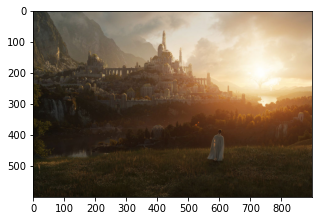

In [35]:
# Загружаем изображение из указанного файла
image = Image.open("2.png")
# Отрисовываем изображение
plt.figure(figsize=(5,5))
plt.imshow(image)
plt.show()

Изображения, с которыми вы работаете, состоят из значений RGB, которые представляют собой значения от 0 до 255. Ноль означает белый шум, он делает изображение зернистым:

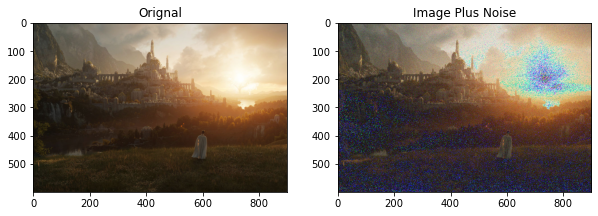

In [36]:
# Получаем количество строк и столбцов в изображении
rows, cols = image.size
'''Создаем значения с использованием нормального распределения со средним значением 0 
и стандартным отклонением 15, значения преобразуются в unit8, это означает, что 
значения находятся в диапазоне от 0 до 255.'''
noise = np.random.normal(0,15,(cols,rows,3)).astype(np.uint8)
# Добавktybt шум к изображению
noisy_image = image + noise
# Создаybtизображение PIL из массива
noisy_image = Image.fromarray(noisy_image)
'''Строим исходное изображение и изображение с шумом, 
используя функцию, которую определеили выше'''
plot_image(image, noisy_image, title_1="Orignal", title_2="Image Plus Noise")

При добавлении шума к изображению иногда значение может быть больше 255, в данном случае 256. Происходит процедура вычитания, чтобы сохранить его между 0 и 255. Например, рассмотрим изображение со значением RGB, равным 137 и добавим к нему шум со значением RGB, равным 215, чтобы получить значение RGB, равное 352. Затем мы вычитаем 256, общее количество возможных значений от 0 до 255, чтобы получить число от 0 до 255.

### Фильтрация шума

Чтобы иметь возможность создавать клиентские ядра и использовать предопределенные фильтры, вы дожете импортировать следующую библиотеку

In [37]:
from PIL import ImageFilter

Сглаживающие фильтры усредняют пиксели в окрестности, их иногда называют фильтрами нижних частот. Для средней фильтрации ядро просто усредняет ядра в окрестности.

In [38]:
'''Создание ядра, которое представляет собой массив 5 на 5, 
где каждое значение равно 1/36'''
kernel = np.ones((5,5))/36
# Создание ядра ImageFilter, с указанием размера ядра и сплющенного ядра
kernel_filter = ImageFilter.Kernel((5,5), kernel.flatten())

Функция <code> filter </code> выполняет свертку между изображением и ядром независимо по каждому цветовому каналу.

In [39]:
# Фильтрация изображения с помощью ядра
image_filtered = noisy_image.filter(kernel_filter)

Вы можете построить изображение до и после фильтрации. Вы видите, что шум уменьшился, но изображение получилось размытым:

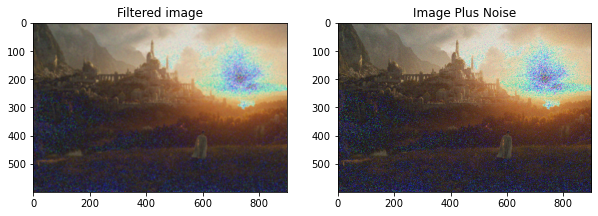

In [40]:
'''Отрисовка отфильтрованного изображения и изображения с шумом, 
используя функцию, определенную сверху'''
plot_image(image_filtered, noisy_image,title_1="Filtered image",title_2="Image Plus Noise")

Меньшее ядро сохраняет резкость изображения, но фильтрует меньше шума, ниже вы будете использовать ядро 3x3. Вы можете видеть, что ее линии более резкие на этом изображении, но зеленый шум ярче, чем на отфильтрованном изображении выше.

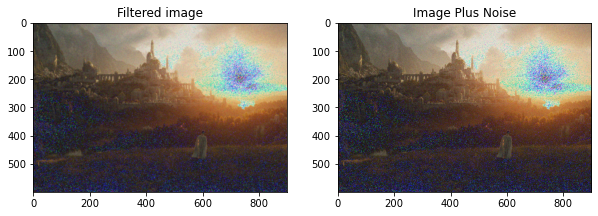

In [41]:
'''Создание ядра, которое представляет собой массив 3 на 3, 
где каждое значение равно 1/36'''
kernel = np.ones((3,3))/36
# Создание ядра ImageFilter, с указанием размера ядра и сплющенного ядра
kernel_filter = ImageFilter.Kernel((3,3), kernel.flatten())
# Фильтрация изображения с помощью ядра
image_filtered = noisy_image.filter(kernel_filter)
'''Отрисовка отфильтрованного изображения и изображения с шумом, 
используя функцию, определенную сверху'''
plot_image(image_filtered, noisy_image,title_1="Filtered image",title_2="Image Plus Noise")

### Размытие по Гауссу

Чтобы выполнить размытие по Гауссу, необходимо применить функцию `filter` к изображению, используя определенный фильтр` ImageFilter.GaussianBlur`

Параметры
<p><code>radius</code>: blur kernel radius, default 2</p>

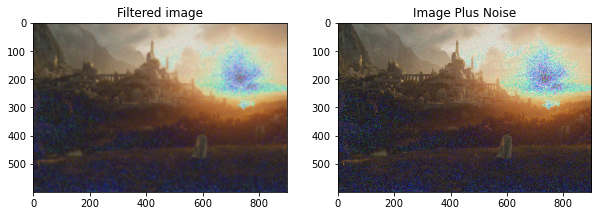

In [42]:
# Фильтрация изображения с помощью GaussianBlur
image_filtered = noisy_image.filter(ImageFilter.GaussianBlur)
# Отрисовка отфильтрованного изображения и нефильтрованного изображения с шумом
plot_image(image_filtered , noisy_image,title_1="Filtered image",title_2="Image Plus Noise")

Пример с использованием ядра 4 на 4

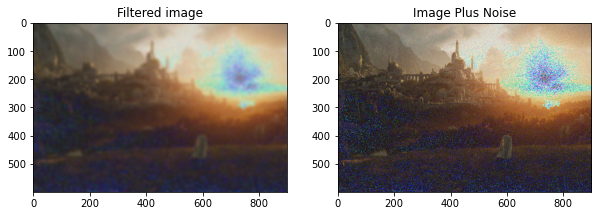

In [43]:
'''Фильтрация изображения с помощью GaussianBlur на изображении 
с шумом, используя ядро 4 на 4.'''
image_filtered = noisy_image.filter(ImageFilter.GaussianBlur(4))
# Отрисвка отфильтрованного изображения и нефильтрованного изображения с шумом
plot_image(image_filtered , noisy_image,title_1="Filtered image",title_2="Image Plus Noise")

### Повышение резкости изображения

Повышение резкости изображения включает в себя сглаживание изображения и вычисление производных. Вы можете добиться повышения резкости изображения, применив следующее ядро.

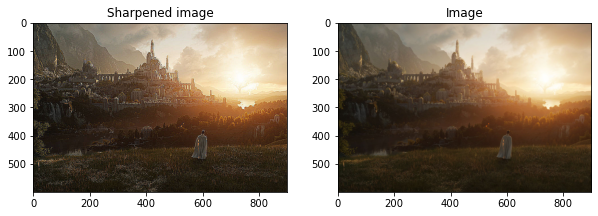

In [44]:
# Общее ядро для повышения резкости изображения
kernel = np.array([[-1,-1,-1], 
                   [-1, 9,-1],
                   [-1,-1,-1]])
kernel = ImageFilter.Kernel((3,3), kernel.flatten())
'''Применяем фильтр повышения резкости с использованием ядра 
к исходному изображению без шума'''
sharpened = image.filter(kernel)
'''Отрисовка изображения с повышенной резкостью и 
исходным изображением без шума'''
plot_image(sharpened, image, title_1="Sharpened image",title_2="Image")

Вы также можем повысить резкость с помощью предустановленного фильтра.

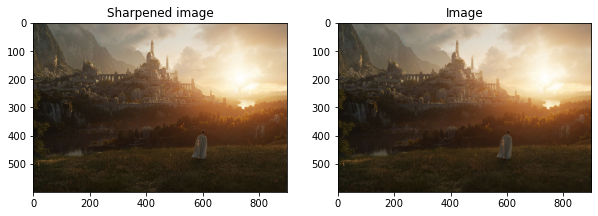

In [45]:
'''Повышение резкости изображения с помощью предопределенного 
фильтра изображения из PIL'''
sharpened = image.filter(ImageFilter.SHARPEN)
''' Отрисовка изображения с повышенной резкостью и 
исходным изображением без шума'''
plot_image(sharpened , image, title_1="Sharpened image",title_2="Image")

## Edges (края)

По краям меняется яркость пикселей. В данном случае, градиент функции выводит скорость изменения. Вы можете аппроксимировать градиент изображения в градациях серого с помощью свертки. Рассмотрим следующее изображение:

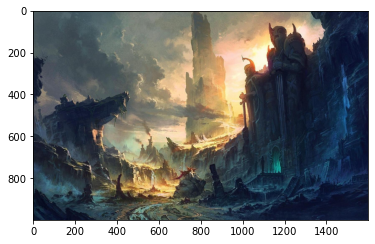

In [46]:
# Загрузка изображения из указанного файла
img_gray = Image.open('3.png')
''' Отрисовываем изображение из массива данных, обратите внимание, что оно двумерное, 
а не трехмерное, потому что у него нет цвета.'''
plt.imshow(img_gray ,cmap='gray')

Вы улучшаете края, чтобы они лучше воспринимались, когда вы используете функцию для обнаружения краев.

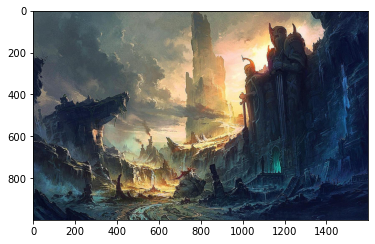

In [47]:
# Фильтрация изображения с помощью фильтра EDGE_ENHANCE
img_gray = img_gray.filter(ImageFilter.EDGE_ENHANCE)
# Отрисовка улучшенного изображения
plt.imshow(img_gray ,cmap='gray')

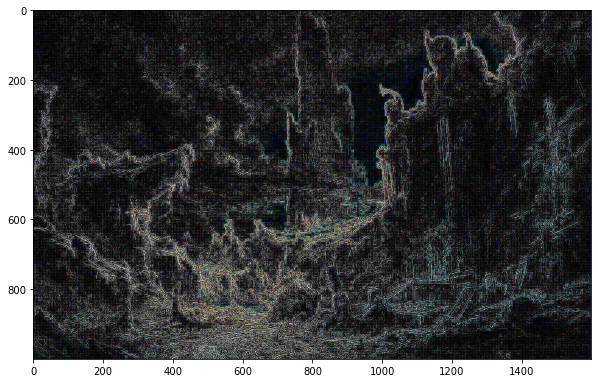

In [48]:
# Фильтрация изображения с помощью фильтра FIND_EDGES
img_gray = img_gray.filter(ImageFilter.FIND_EDGES)
# Отрисовка отфильтрованного изображения
plt.figure(figsize=(10,10))
plt.imshow(img_gray ,cmap='gray')

## Медиана

Медианные фильтры находят медианное значение всех пикселей под областью ядра, и центральный элемент заменяется этим медианным значением.

Вы можете применять медианные фильтры к обычным изображениям. Рассмотрим использование медианного фильтра для улучшения сегментации.

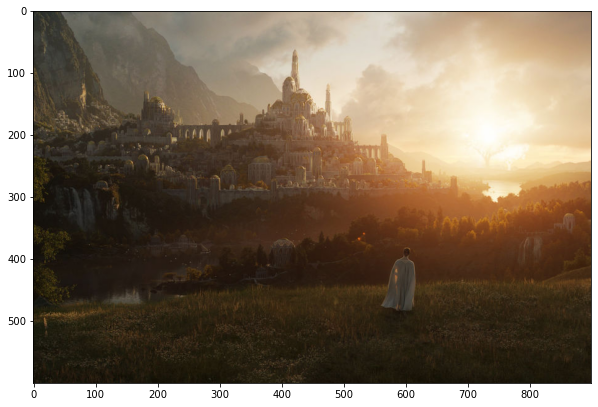

In [49]:
# Загружаем изображение
image = Image.open("2.png")
# Увеличение изображения при отрисовке
plt.figure(figsize=(10,10))
# Отрислвка изображения
plt.imshow(image,cmap="gray")

Медианная фильтрация размывает фон, увеличивая сегментацию между объектами и фоном.

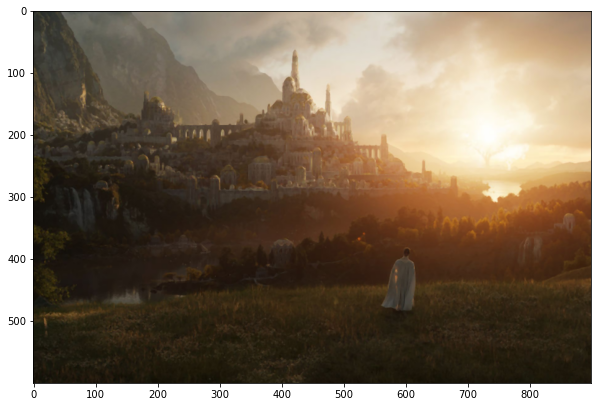

In [50]:
image = image.filter(ImageFilter.MedianFilter)
plt.figure(figsize=(10,10))
# Отрисовка изображения
plt.imshow(image,cmap="gray")